In [1]:
#%pip install netCDF4
#%pip install metpy
#%pip install scienceplots

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import xarray as xr
from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter
import metpy.calc as mpcalc # to calculate wet bulb potential temp
from metpy.units import units
from metpy.plots import ColdFront, WarmFront, OccludedFront

out_dir = Path("/home/ellen/git projects/phys-met/output_era_plots")
out_dir.mkdir(parents=True, exist_ok=True)

In [3]:
ERA5_file = "/home/ellen/git projects/phys-met/era5-wet-bulb.nc"

NCDATA = xr.open_dataset(ERA5_file)
NCDATA

<xarray.Dataset> Size: 48MB
Dimensions:         (valid_time: 72, pressure_level: 1, latitude: 169,
                     longitude: 495)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 576B 2026-01-26 ... 2026-01-2...
    expver          (valid_time) <U4 1kB ...
  * pressure_level  (pressure_level) float64 8B 850.0
  * latitude        (latitude) float64 1kB 68.0 67.75 67.5 ... 26.5 26.25 26.0
  * longitude       (longitude) float64 4kB -55.75 -55.5 -55.25 ... 67.5 67.75
    number          int64 8B ...
Data variables:
    q               (valid_time, pressure_level, latitude, longitude) float32 24MB ...
    t               (valid_time, pressure_level, latitude, longitude) float32 24MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-10T16:02 GRIB to CDM+CF via cfgrib-0.9.1...

In [4]:
p = 850 * units.hPa # fixed at 850 hPa
T = NCDATA['t'].metpy.quantify() # temperature
q = NCDATA['q'].metpy.quantify() # specific humidity 


In [5]:
from metpy.calc import dewpoint_from_specific_humidity

dewpoint = dewpoint_from_specific_humidity(p, q)

In [6]:
from metpy.calc import wet_bulb_potential_temperature

wet_bulb = wet_bulb_potential_temperature(p, T, dewpoint)

In [7]:
# claude suggestions

tw = wet_bulb.metpy.convert_units("degC").metpy.dequantify()

# drop the single 850 hPa level, and rename the time dimension if needed
tw = tw.squeeze(drop=True)
if "valid_time" in tw.dims:
    tw = tw.rename({"valid_time": "time"})

print(tw.dims)    # should be ('time', 'latitude', 'longitude')
print(f"θw range: {float(tw.min()):.1f} to {float(tw.max()):.1f} °C")

('time', 'latitude', 'longitude')
θw range: -17.4 to 19.2 °C


In [19]:
# mark Chandra's low centre and central pressure 
msl = xr.open_dataset("/home/ellen/git projects/phys-met/era-5-mslp.nc")   
if "valid_time" in msl.dims:
    msl = msl.rename({"valid_time": "time"})

p_hpa = msl["msl"].sel(time=np.datetime64(TIME)) / 100        # Pa -> hPa

# search only near Chandra, so the other low (Storm Joseph, further west) isn't picked by mistake
search = p_hpa.sel(latitude=slice(60, 45), longitude=slice(-20, 5))
lowest = search.where(search == search.min(), drop=True)
lon_L, lat_L = float(lowest.longitude[0]), float(lowest.latitude[0])
p_min = float(search.min())

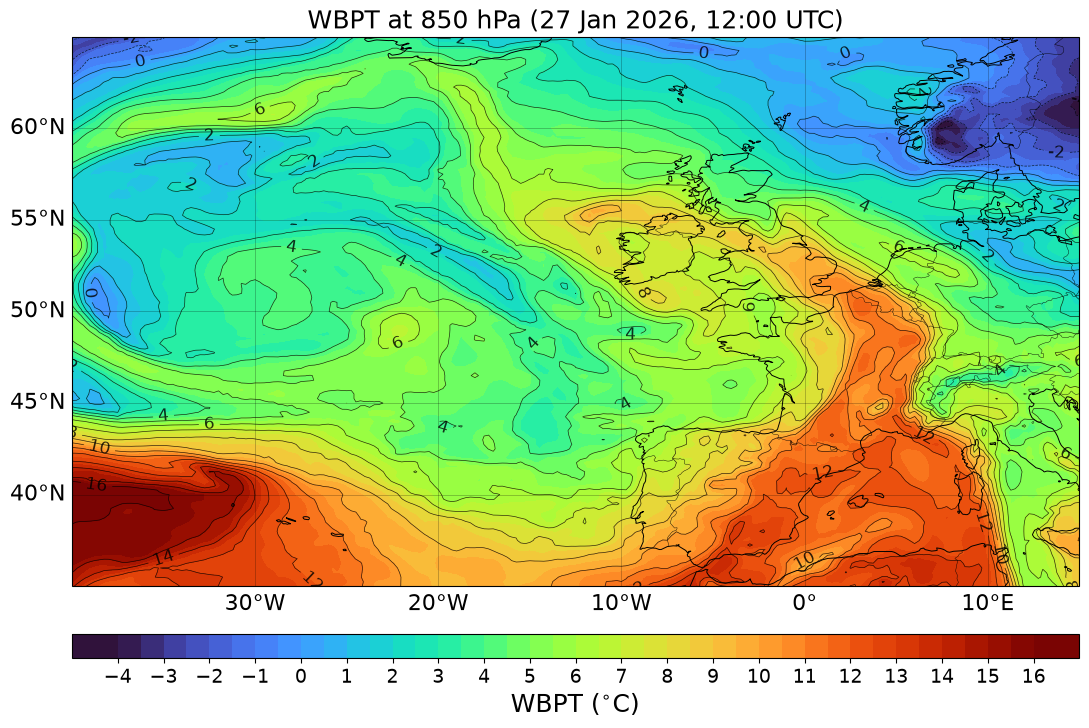

In [47]:
# ---- settings ----
TIME = "2026-01-27T12:00"          # same time as Angela's frame
EXT = [-40, 15, 35, 65]           # west, east, south, north (zoomed on Chandra)


VMIN, VMAX = -4, 16

pc = ccrs.PlateCarree()
field = tw.sel(time=np.datetime64(TIME)).sel(
    longitude=slice(EXT[0] - 1, EXT[1] + 1),
    latitude=slice(EXT[3] + 1, EXT[2] - 1),
)
t = pd.Timestamp(field.time.values)

fig = plt.figure(figsize=(13, 8))   # wider, to fit a label at every 1 °C
ax = plt.axes(projection=pc)
ax.set_extent(EXT, crs=pc)

# 1. θw shading + a line every 1 °C: fronts = where the lines bunch together
cf = ax.contourf(field.longitude, field.latitude, field,
                 levels=np.arange(VMIN, VMAX + 0.5, 0.5), cmap="turbo",
                 extend="both", transform=pc)
cs = ax.contour(field.longitude, field.latitude, field,
                levels=np.arange(VMIN, VMAX + 1, 1), colors="black",
                linewidths=0.5, alpha=0.8, transform=pc)
ax.clabel(cs, levels=np.arange(VMIN, VMAX + 1, 2), fmt="%d", fontsize=12)


# map details
ax.coastlines("50m", color="black", linewidth=0.7)
ax.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.3)
gl = ax.gridlines(draw_labels=True, linewidth=0.4, color="black", alpha=0.4)
#gl = ax.gridlines(draw_labels=True, xlocs=range(-30, 11, 1), ylocs=range(35, 63, 1),
                  #linewidth=0.3, color="black", alpha=0.4)
gl.top_labels = gl.right_labels = False
gl.xlabel_style = gl.ylabel_style = {"size": 16}

# rectangular colour bar with a label at every 1 °C
fig.canvas.draw()                                   # so the map's final size is known
pos = ax.get_position()
cax = fig.add_axes([pos.x0, pos.y0 - 0.09, pos.width, 0.03])

cbar = fig.colorbar(cf, cax=cax, orientation="horizontal", extendrect=True,
                    ticks=np.arange(VMIN, VMAX + 1, 1))
cbar.ax.tick_params(labelsize=14)
cbar.set_label(r"WBPT ($^{\circ}\mathrm{C}$)", fontsize=18)
ax.set_title(f"WBPT at 850 hPa ({t:%d %b %Y, %H:%M} UTC)", fontsize=18)

fig.savefig(out_dir / f"wbpt_{t:%Y%m%d_%H%M}.png", dpi=150, bbox_inches="tight")
plt.show()